In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sqlalchemy import create_engine, text
import warnings
warnings.filterwarnings("ignore")

# ── Style ──────────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "figure.dpi":      150,
    "figure.figsize":  (12, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize":  14,
    "axes.titleweight": "bold",
    "font.family":     "sans-serif",
})
sns.set_palette("Blues_r")

# ── Connect ────────────────────────────────────────────────────────────────────
DB_PATH = r"D:\customer_intelligence_platform\data\processed\olist.db"
engine  = create_engine(f"sqlite:///{DB_PATH}")

def sql(query):
    """Run a SQL query and return a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(query), conn)

print("Connected to database")
print(sql("SELECT COUNT(*) as total_orders FROM master_orders"))

Connected to database
   total_orders
0         99436


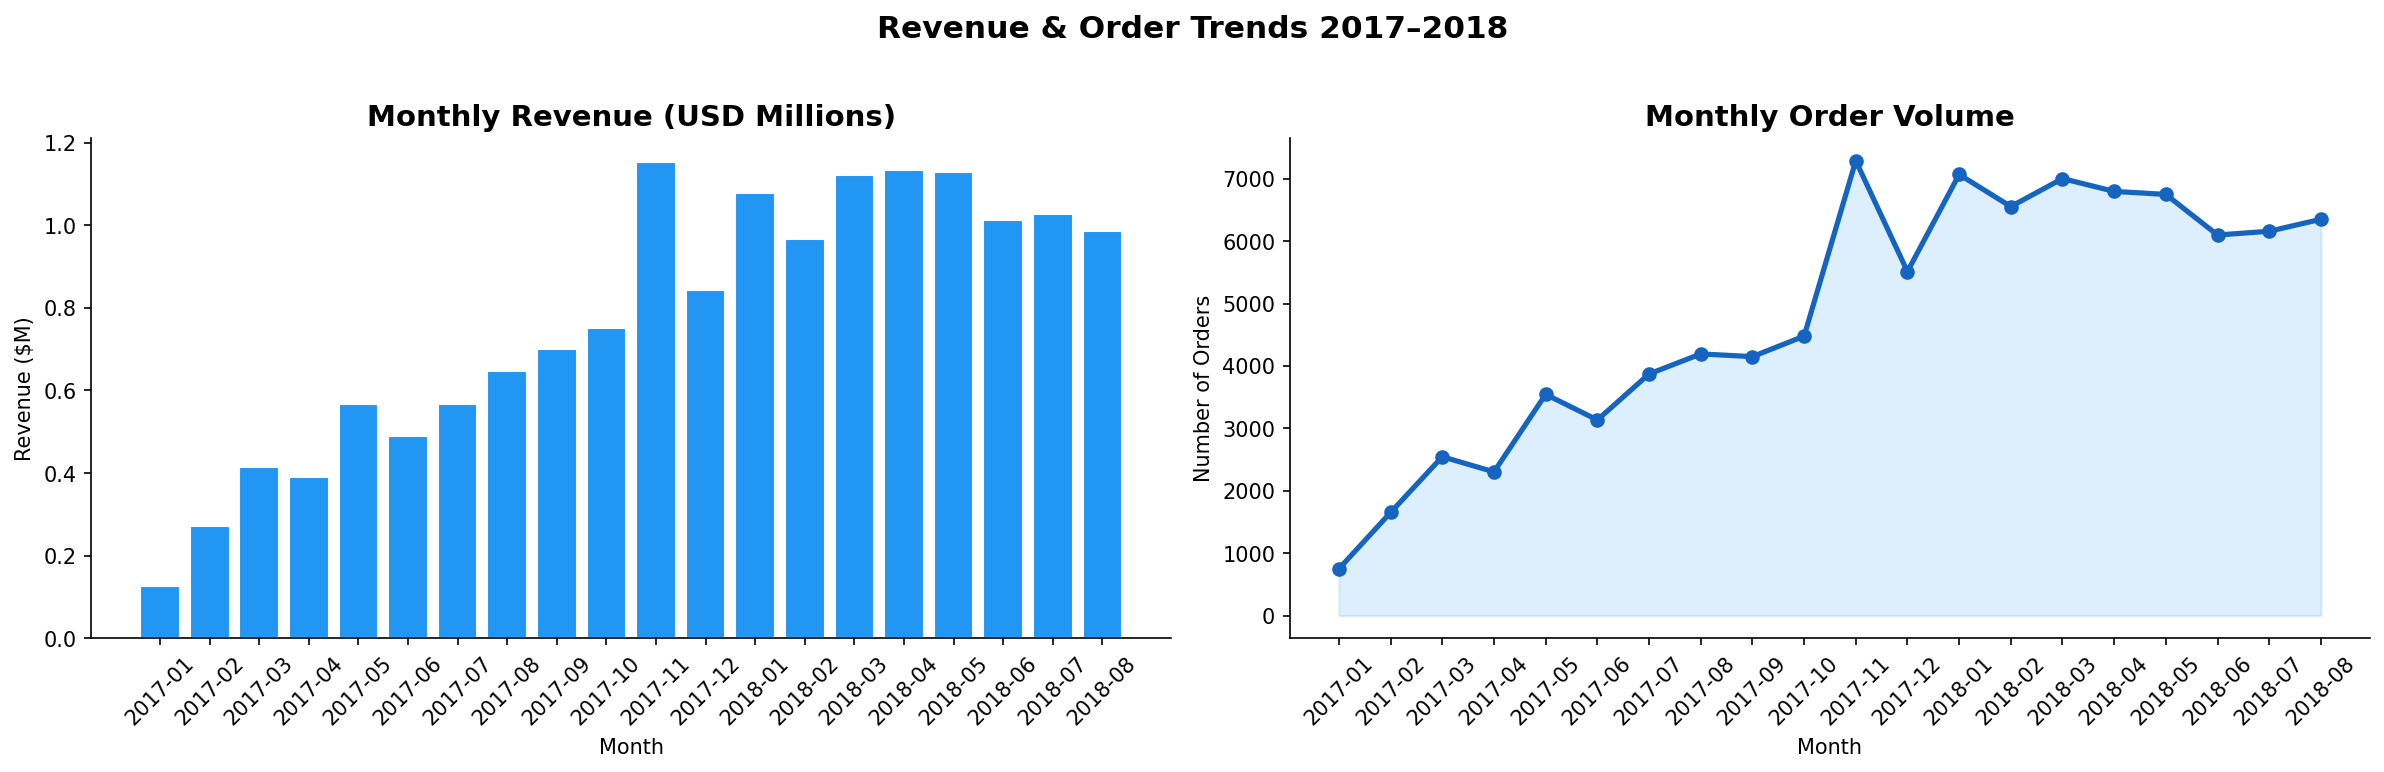


Insight: Peak revenue month was 2017-11 at $1,153,528


In [6]:
# ── Q1: Monthly revenue trend ─────────────────────────────────────────────────
monthly_revenue = sql("""
    SELECT 
        purchase_year  AS year,
        purchase_month AS month,
        ROUND(SUM(total_payment), 2)   AS revenue,
        COUNT(order_id)                AS num_orders,
        ROUND(AVG(total_payment), 2)   AS avg_order_value
    FROM master_orders
    WHERE order_status = 'delivered'
      AND purchase_year IN (2017, 2018)
    GROUP BY purchase_year, purchase_month
    ORDER BY purchase_year, purchase_month
""")

monthly_revenue["period"] = (
    monthly_revenue["year"].astype(str) + "-" +
    monthly_revenue["month"].astype(str).str.zfill(2)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Revenue
axes[0].bar(monthly_revenue["period"], monthly_revenue["revenue"] / 1e6,
            color="#2196F3", edgecolor="white")
axes[0].set_title("Monthly Revenue (USD Millions)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue ($M)")
axes[0].tick_params(axis="x", rotation=45)

# Order volume
axes[1].plot(monthly_revenue["period"], monthly_revenue["num_orders"],
             marker="o", color="#1565C0", linewidth=2.5)
axes[1].fill_between(range(len(monthly_revenue)),
                     monthly_revenue["num_orders"], alpha=0.15, color="#2196F3")
axes[1].set_xticks(range(len(monthly_revenue)))
axes[1].set_xticklabels(monthly_revenue["period"], rotation=45)
axes[1].set_title("Monthly Order Volume")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Number of Orders")

plt.suptitle("Revenue & Order Trends 2017–2018", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(r"D:\customer_intelligence_platform\outputs\01_revenue_trend.png",
            bbox_inches="tight")
plt.show()

print(f"\nInsight: Peak revenue month was "
      f"{monthly_revenue.loc[monthly_revenue.revenue.idxmax(), 'period']} "
      f"at ${monthly_revenue.revenue.max():,.0f}")

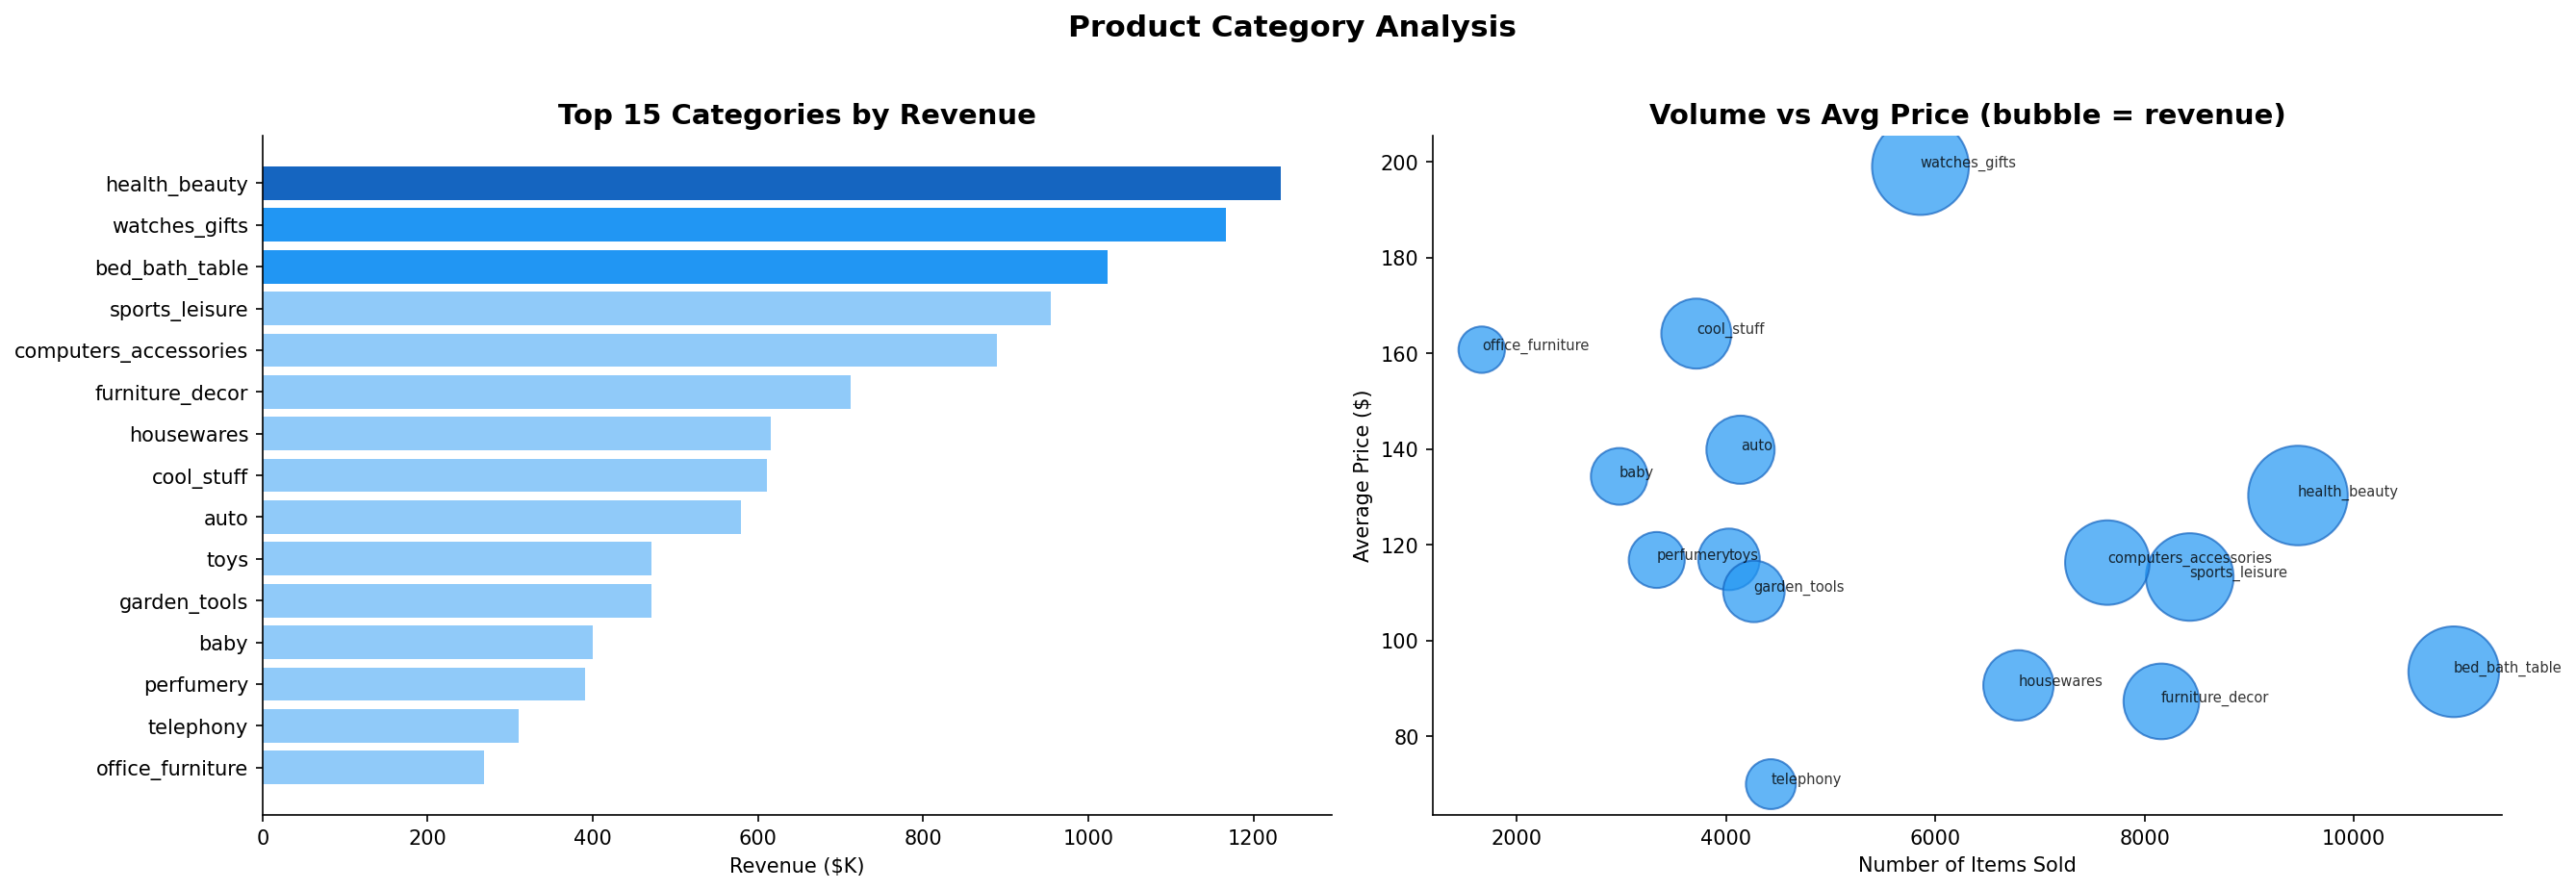


Top 5 Categories:
                category     revenue  num_items  avg_price
0          health_beauty  1233131.72       9465     130.28
1          watches_gifts  1166176.98       5859     199.04
2         bed_bath_table  1023434.76      10953      93.44
3         sports_leisure   954852.55       8431     113.25
4  computers_accessories   888724.61       7644     116.26


In [7]:
# ── Q2: Top 15 categories by revenue ─────────────────────────────────────────
category_rev = sql("""
    SELECT 
        mi.product_category_name_english AS category,
        ROUND(SUM(mi.price), 2)          AS revenue,
        COUNT(*)                         AS num_items,
        ROUND(AVG(mi.price), 2)          AS avg_price
    FROM master_items mi
    JOIN master_orders mo ON mi.order_id = mo.order_id
    WHERE mo.order_status = 'delivered'
    GROUP BY category
    ORDER BY revenue DESC
    LIMIT 15
""")

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Revenue bar
colors = ["#1565C0" if i == 0 else "#2196F3" if i < 3 else "#90CAF9"
          for i in range(len(category_rev))]
axes[0].barh(category_rev["category"][::-1],
             category_rev["revenue"][::-1] / 1e3, color=colors[::-1])
axes[0].set_title("Top 15 Categories by Revenue")
axes[0].set_xlabel("Revenue ($K)")

# Avg price scatter
axes[1].scatter(category_rev["num_items"], category_rev["avg_price"],
                s=category_rev["revenue"] / 500, alpha=0.7,
                color="#2196F3", edgecolors="#1565C0")
for _, row in category_rev.iterrows():
    axes[1].annotate(row["category"],
                     (row["num_items"], row["avg_price"]),
                     fontsize=7, alpha=0.8)
axes[1].set_title("Volume vs Avg Price (bubble = revenue)")
axes[1].set_xlabel("Number of Items Sold")
axes[1].set_ylabel("Average Price ($)")

plt.suptitle("Product Category Analysis", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(r"D:\customer_intelligence_platform\outputs\02_category_analysis.png",
            bbox_inches="tight")
plt.show()

print("\nTop 5 Categories:")
print(category_rev[["category","revenue","num_items","avg_price"]].head())

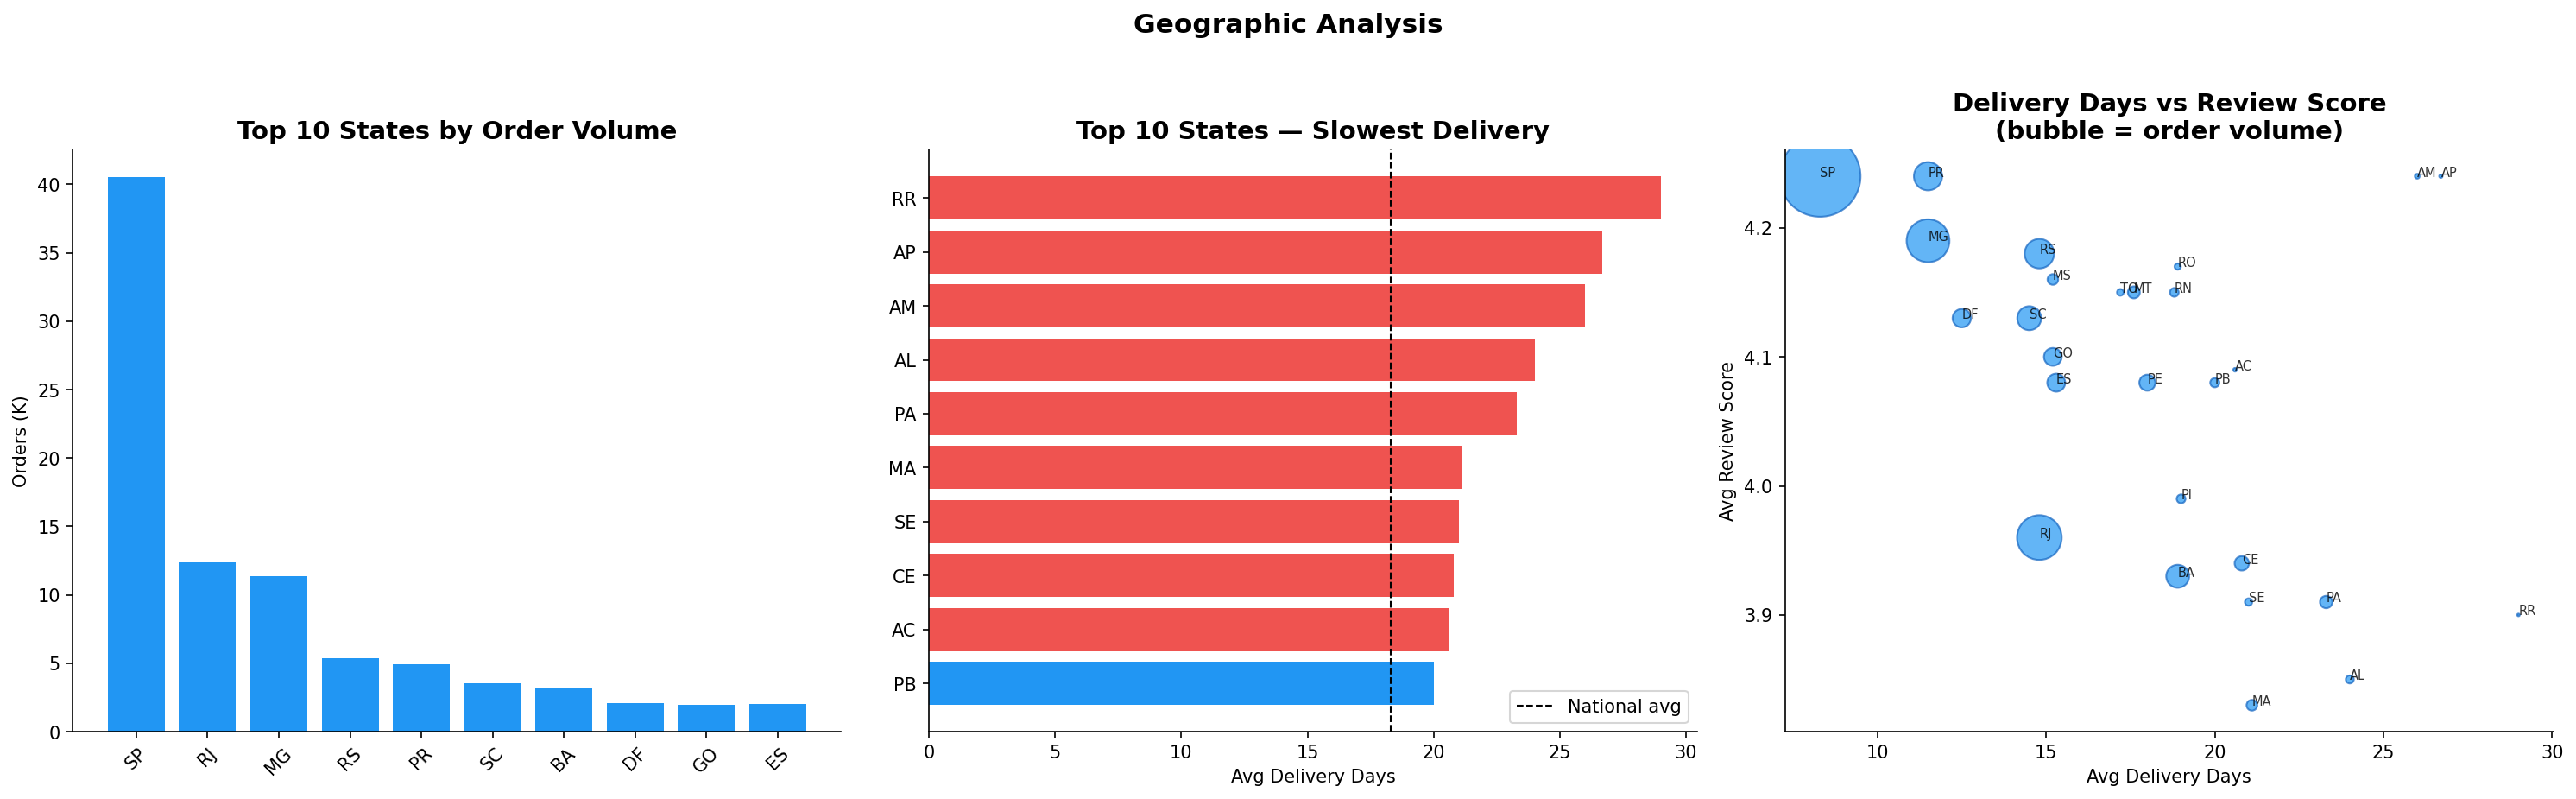


Insight: States with delivery > 20 days avg review = 3.99 vs 4.12 for faster states


In [8]:
# ── Q3: Revenue and orders by state ──────────────────────────────────────────
state_stats = sql("""
    SELECT 
        customer_state                        AS state,
        COUNT(order_id)                       AS num_orders,
        ROUND(SUM(total_payment), 2)          AS revenue,
        ROUND(AVG(total_payment), 2)          AS avg_order_value,
        ROUND(AVG(delivery_days), 1)          AS avg_delivery_days,
        ROUND(AVG(review_score), 2)           AS avg_review
    FROM master_orders
    WHERE order_status = 'delivered'
    GROUP BY customer_state
    ORDER BY revenue DESC
""")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Orders by state
top_states = state_stats.head(10)
axes[0].bar(top_states["state"], top_states["num_orders"] / 1e3,
            color="#2196F3")
axes[0].set_title("Top 10 States by Order Volume")
axes[0].set_ylabel("Orders (K)")
axes[0].tick_params(axis="x", rotation=45)

# Avg delivery days
delivery_sorted = state_stats.sort_values("avg_delivery_days", ascending=False).head(10)
axes[1].barh(delivery_sorted["state"][::-1],
             delivery_sorted["avg_delivery_days"][::-1],
             color=["#EF5350" if x > 20 else "#2196F3"
                    for x in delivery_sorted["avg_delivery_days"][::-1]])
axes[1].set_title("Top 10 States — Slowest Delivery")
axes[1].set_xlabel("Avg Delivery Days")
axes[1].axvline(state_stats["avg_delivery_days"].mean(),
                color="black", linestyle="--", linewidth=1, label="National avg")
axes[1].legend()

# Review score vs delivery days
axes[2].scatter(state_stats["avg_delivery_days"],
                state_stats["avg_review"],
                s=state_stats["num_orders"] / 20,
                alpha=0.7, color="#2196F3", edgecolors="#1565C0")
for _, row in state_stats.iterrows():
    axes[2].annotate(row["state"],
                     (row["avg_delivery_days"], row["avg_review"]),
                     fontsize=7, alpha=0.8)
axes[2].set_title("Delivery Days vs Review Score\n(bubble = order volume)")
axes[2].set_xlabel("Avg Delivery Days")
axes[2].set_ylabel("Avg Review Score")

plt.suptitle("Geographic Analysis", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(r"D:\customer_intelligence_platform\outputs\03_geographic_analysis.png",
            bbox_inches="tight")
plt.show()

print(f"\nInsight: States with delivery > 20 days avg review = "
      f"{state_stats[state_stats.avg_delivery_days > 20].avg_review.mean():.2f} "
      f"vs {state_stats[state_stats.avg_delivery_days <= 20].avg_review.mean():.2f} for faster states")

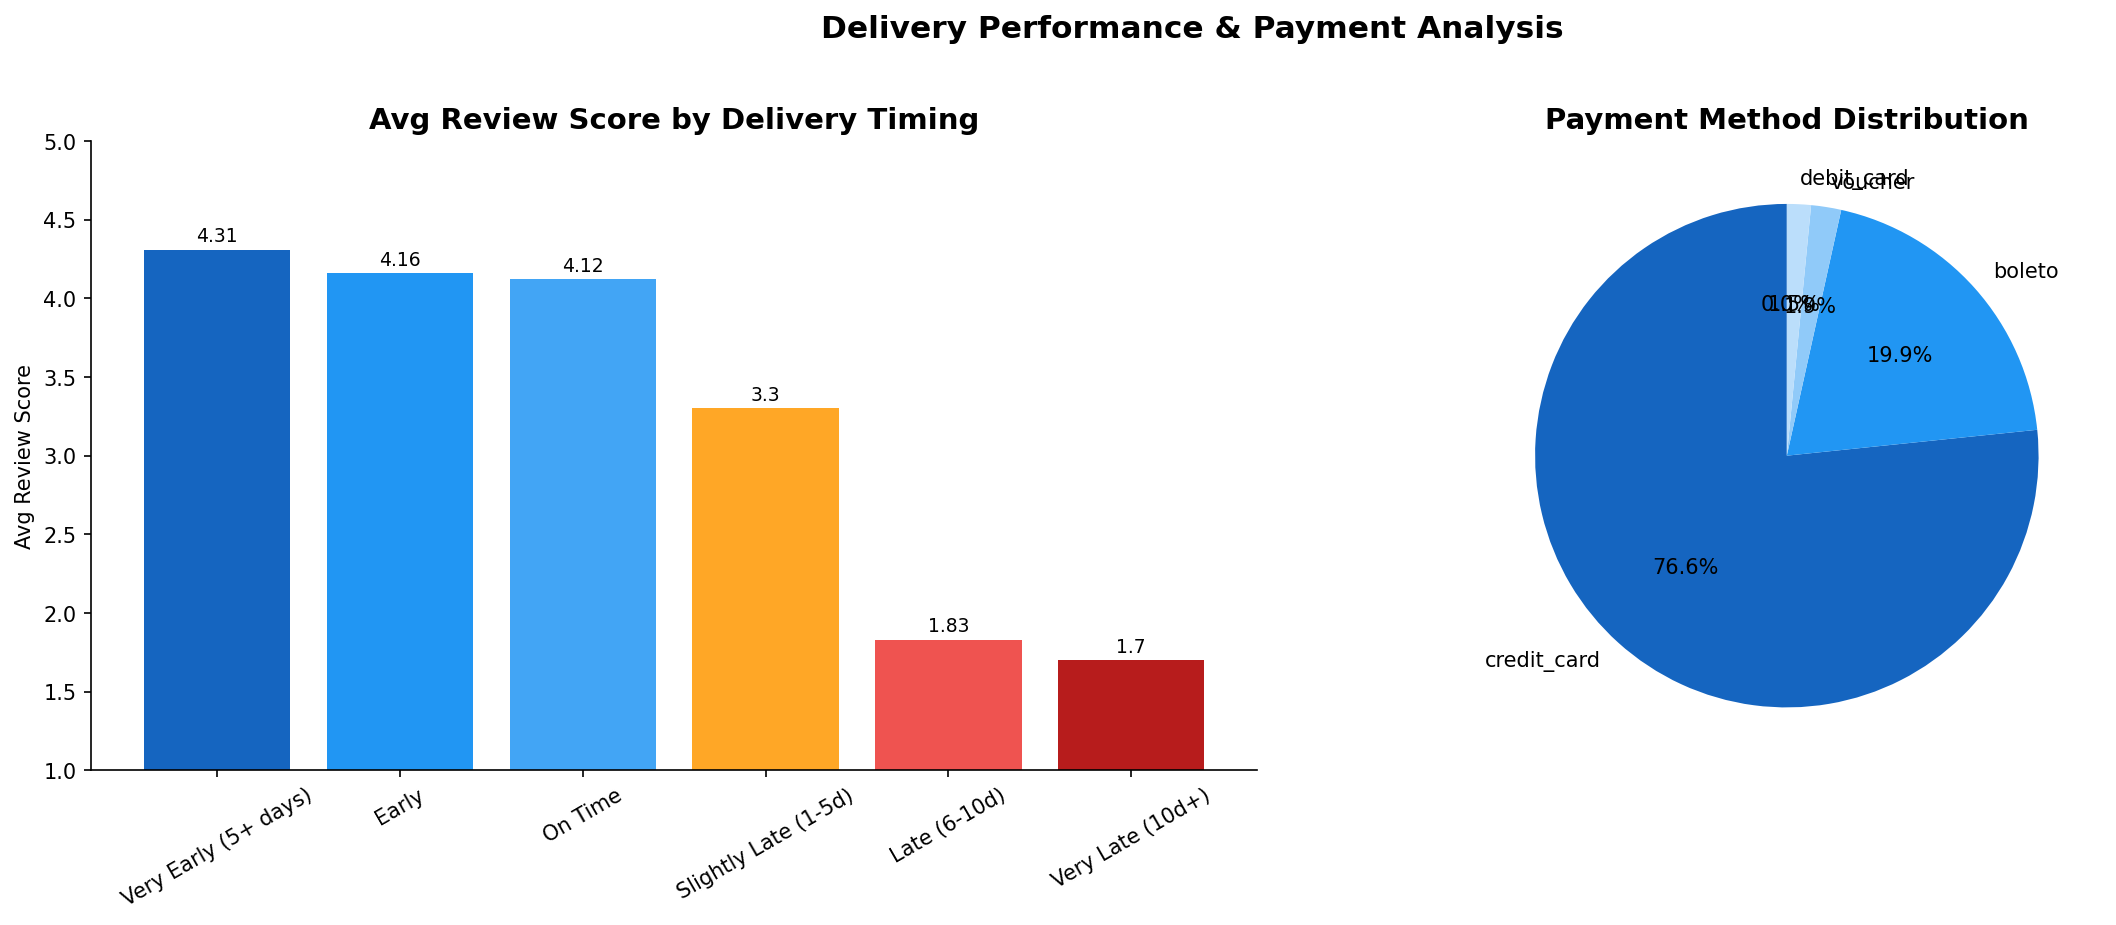


Key Insight — Review scores by delivery:
     delivery_bucket  avg_review  num_orders
Very Early (5+ days)        4.31       77701
               Early        4.16       10082
             On Time        4.12        1380
Slightly Late (1-5d)        3.30        3289
        Late (6-10d)        1.83        1815
    Very Late (10d+)        1.70        2203


In [9]:
# ── Q4: How delivery delay impacts review score ───────────────────────────────
delay_review = sql("""
    SELECT
        CASE
            WHEN delivery_delay_days < -5  THEN 'Very Early (5+ days)'
            WHEN delivery_delay_days < 0   THEN 'Early'
            WHEN delivery_delay_days = 0   THEN 'On Time'
            WHEN delivery_delay_days <= 5  THEN 'Slightly Late (1-5d)'
            WHEN delivery_delay_days <= 10 THEN 'Late (6-10d)'
            ELSE 'Very Late (10d+)'
        END AS delivery_bucket,
        ROUND(AVG(review_score), 2) AS avg_review,
        COUNT(*)                    AS num_orders
    FROM master_orders
    WHERE order_status = 'delivered'
      AND delivery_delay_days IS NOT NULL
    GROUP BY delivery_bucket
    ORDER BY avg_review DESC
""")

payment_dist = sql("""
    SELECT 
        payment_type,
        COUNT(*)                       AS num_orders,
        ROUND(SUM(total_payment), 2)   AS total_revenue,
        ROUND(AVG(total_payment), 2)   AS avg_order_value
    FROM master_orders
    WHERE order_status = 'delivered'
    GROUP BY payment_type
    ORDER BY num_orders DESC
""")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Delivery impact on review
order = ["Very Early (5+ days)", "Early", "On Time",
         "Slightly Late (1-5d)", "Late (6-10d)", "Very Late (10d+)"]
delay_review["delivery_bucket"] = pd.Categorical(
    delay_review["delivery_bucket"], categories=order, ordered=True)
delay_review = delay_review.sort_values("delivery_bucket")

bar_colors = ["#1565C0", "#2196F3", "#42A5F5", "#FFA726", "#EF5350", "#B71C1C"]
bars = axes[0].bar(delay_review["delivery_bucket"],
                   delay_review["avg_review"], color=bar_colors)
axes[0].set_title("Avg Review Score by Delivery Timing")
axes[0].set_ylabel("Avg Review Score")
axes[0].set_ylim(1, 5)
axes[0].tick_params(axis="x", rotation=30)
for bar, val in zip(bars, delay_review["avg_review"]):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.05, f"{val}", ha="center", fontsize=9)

# Payment type
axes[1].pie(payment_dist["num_orders"],
            labels=payment_dist["payment_type"],
            autopct="%1.1f%%",
            colors=["#1565C0", "#2196F3", "#90CAF9", "#BBDEFB"],
            startangle=90)
axes[1].set_title("Payment Method Distribution")

plt.suptitle("Delivery Performance & Payment Analysis",
             fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(r"D:\customer_intelligence_platform\outputs\04_delivery_review_analysis.png",
            bbox_inches="tight")
plt.show()

print("\nKey Insight — Review scores by delivery:")
print(delay_review[["delivery_bucket", "avg_review", "num_orders"]].to_string(index=False))

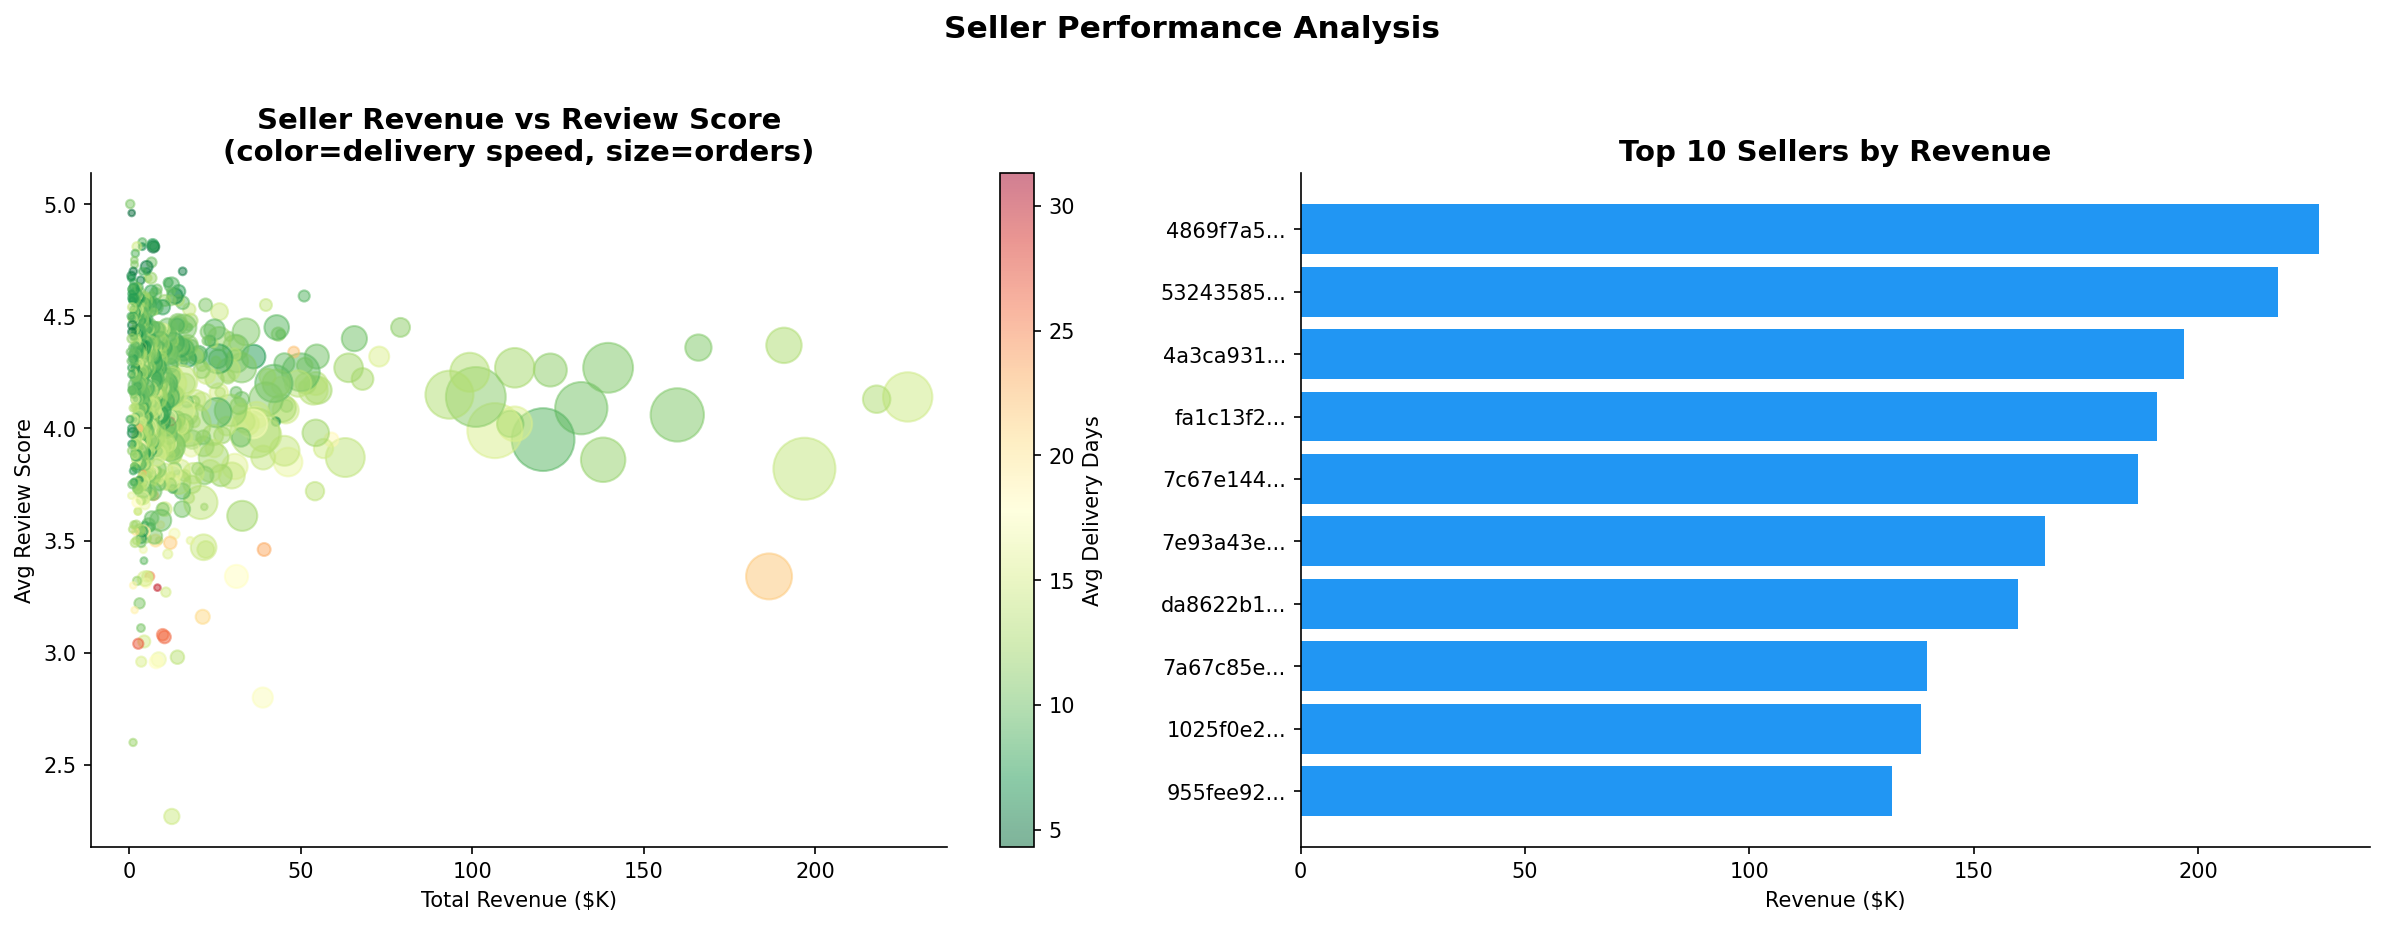


Total sellers analyzed (20+ orders): 804
   Top seller revenue: $226,988
   Avg review across sellers: 4.13


In [10]:
# ── Q5: Seller performance analysis ──────────────────────────────────────────
seller_perf = sql("""
    SELECT
        mi.seller_id,
        mi.seller_state,
        COUNT(DISTINCT mi.order_id)          AS num_orders,
        ROUND(SUM(mi.price), 2)              AS total_revenue,
        ROUND(AVG(mo.review_score), 2)       AS avg_review,
        ROUND(AVG(mo.delivery_days), 1)      AS avg_delivery_days,
        ROUND(AVG(mi.price), 2)              AS avg_item_price
    FROM master_items mi
    JOIN master_orders mo ON mi.order_id = mo.order_id
    WHERE mo.order_status = 'delivered'
    GROUP BY mi.seller_id, mi.seller_state
    HAVING num_orders >= 20
    ORDER BY total_revenue DESC
""")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Revenue vs review score
sc = axes[0].scatter(
    seller_perf["total_revenue"] / 1e3,
    seller_perf["avg_review"],
    s=seller_perf["num_orders"] / 2,
    alpha=0.5,
    c=seller_perf["avg_delivery_days"],
    cmap="RdYlGn_r"
)
plt.colorbar(sc, ax=axes[0], label="Avg Delivery Days")
axes[0].set_title("Seller Revenue vs Review Score\n(color=delivery speed, size=orders)")
axes[0].set_xlabel("Total Revenue ($K)")
axes[0].set_ylabel("Avg Review Score")

# Top 10 sellers by revenue
top_sellers = seller_perf.head(10).copy()
top_sellers["seller_short"] = top_sellers["seller_id"].str[:8] + "..."
axes[1].barh(top_sellers["seller_short"][::-1],
             top_sellers["total_revenue"][::-1] / 1e3,
             color="#2196F3")
axes[1].set_title("Top 10 Sellers by Revenue")
axes[1].set_xlabel("Revenue ($K)")

plt.suptitle("Seller Performance Analysis",
             fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(r"D:\customer_intelligence_platform\outputs\05_seller_analysis.png",
            bbox_inches="tight")
plt.show()

print(f"\nTotal sellers analyzed (20+ orders): {len(seller_perf):,}")
print(f"   Top seller revenue: ${seller_perf.total_revenue.max():,.0f}")
print(f"   Avg review across sellers: {seller_perf.avg_review.mean():.2f}")

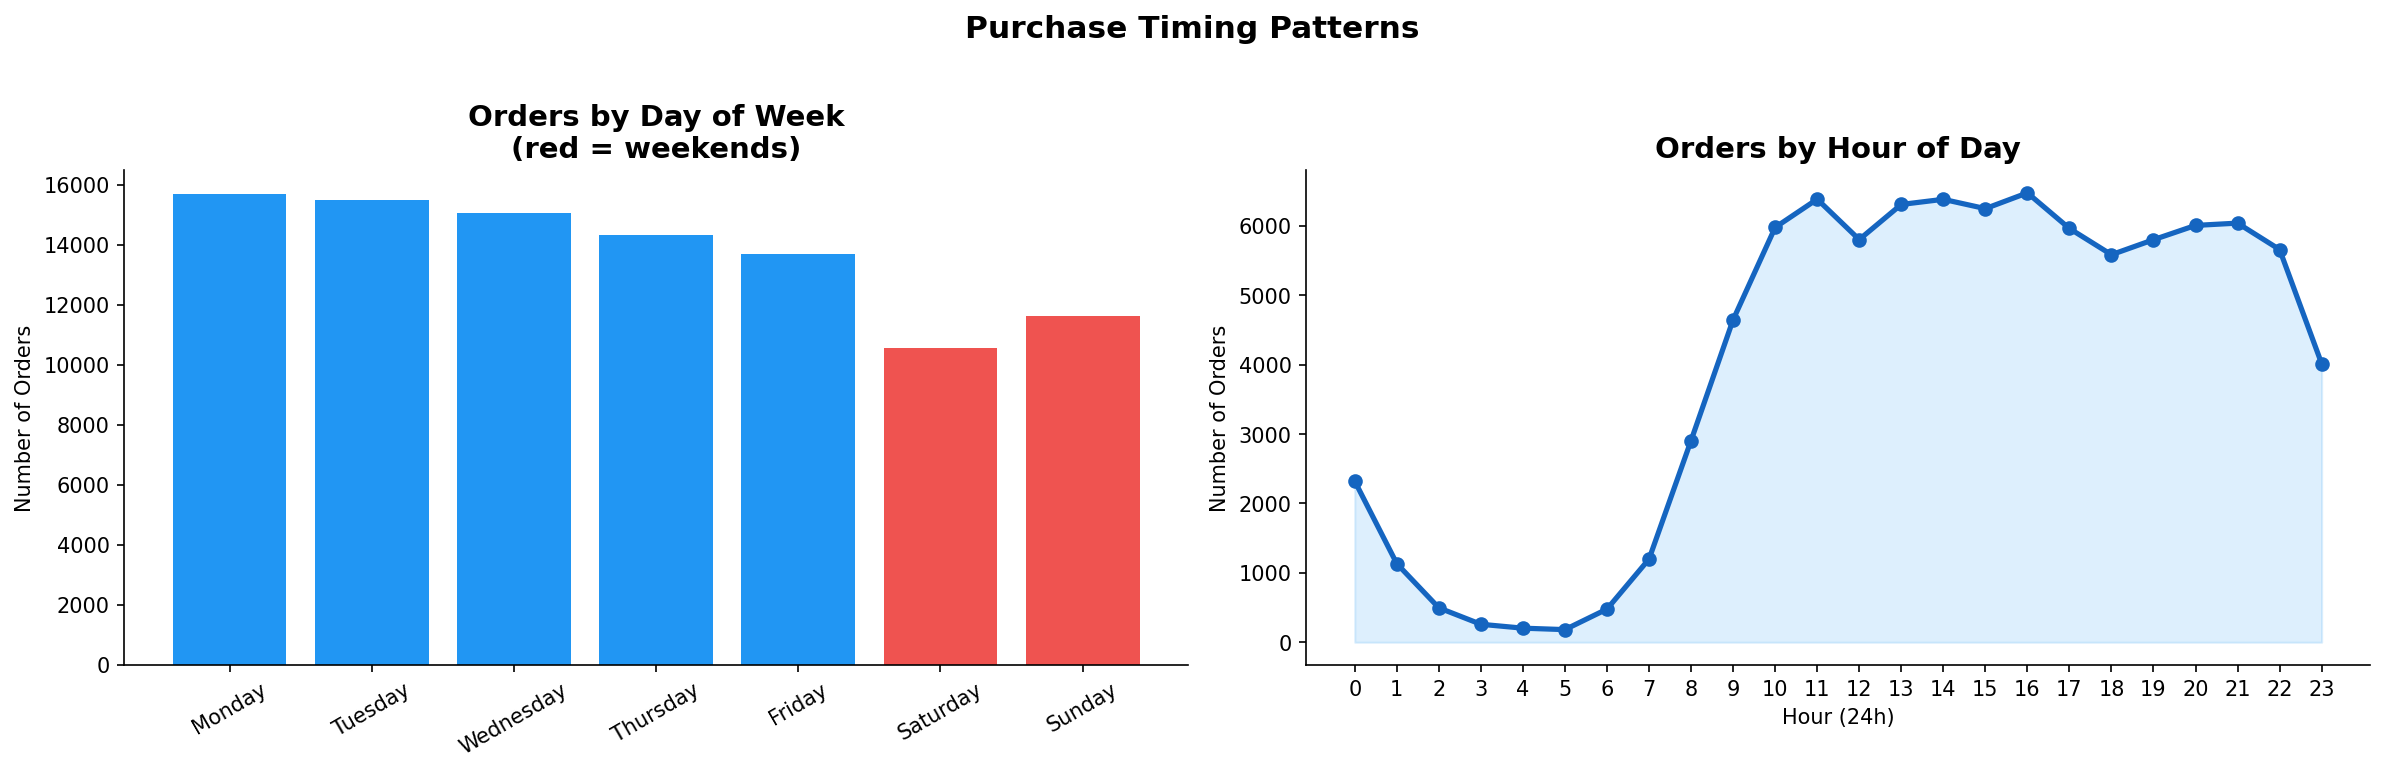


Peak buying hour: 16:00  |  Peak day: Monday


In [11]:
# ── Q6: When do customers buy? ────────────────────────────────────────────────
dow_stats = sql("""
    SELECT
        purchase_dow                    AS day_of_week,
        COUNT(*)                        AS num_orders,
        ROUND(AVG(total_payment), 2)    AS avg_order_value
    FROM master_orders
    WHERE order_status = 'delivered'
    GROUP BY purchase_dow
""")

hour_stats = sql("""
    SELECT
        CAST(strftime('%H', order_purchase_timestamp) AS INTEGER) AS hour,
        COUNT(*) AS num_orders
    FROM master_orders
    WHERE order_status = 'delivered'
    GROUP BY hour
    ORDER BY hour
""")

# Order days properly
day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
dow_stats["day_of_week"] = pd.Categorical(
    dow_stats["day_of_week"], categories=day_order, ordered=True)
dow_stats = dow_stats.sort_values("day_of_week")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].bar(dow_stats["day_of_week"], dow_stats["num_orders"],
            color=["#EF5350" if d in ["Saturday","Sunday"] else "#2196F3"
                   for d in dow_stats["day_of_week"]])
axes[0].set_title("Orders by Day of Week\n(red = weekends)")
axes[0].set_ylabel("Number of Orders")
axes[0].tick_params(axis="x", rotation=30)

axes[1].plot(hour_stats["hour"], hour_stats["num_orders"],
             marker="o", color="#1565C0", linewidth=2.5)
axes[1].fill_between(hour_stats["hour"], hour_stats["num_orders"],
                     alpha=0.15, color="#2196F3")
axes[1].set_title("Orders by Hour of Day")
axes[1].set_xlabel("Hour (24h)")
axes[1].set_ylabel("Number of Orders")
axes[1].set_xticks(range(0, 24))

plt.suptitle("Purchase Timing Patterns",
             fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(r"D:\customer_intelligence_platform\outputs\06_timing_analysis.png",
            bbox_inches="tight")
plt.show()

peak_hour = hour_stats.loc[hour_stats.num_orders.idxmax(), "hour"]
peak_day  = dow_stats.loc[dow_stats.num_orders.idxmax(), "day_of_week"]
print(f"\nPeak buying hour: {peak_hour}:00  |  Peak day: {peak_day}")

In [12]:
# ── Final summary of all key metrics ─────────────────────────────────────────
summary = sql("""
    SELECT
        COUNT(DISTINCT order_id)                        AS total_orders,
        COUNT(DISTINCT customer_unique_id)              AS unique_customers,
        ROUND(SUM(total_payment), 0)                    AS total_revenue,
        ROUND(AVG(total_payment), 2)                    AS avg_order_value,
        ROUND(AVG(review_score), 2)                     AS avg_review_score,
        ROUND(AVG(delivery_days), 1)                    AS avg_delivery_days,
        ROUND(AVG(delivery_delay_days), 1)              AS avg_delay_days,
        SUM(CASE WHEN delivery_delay_days > 0
                 THEN 1 ELSE 0 END) * 100.0 /
            COUNT(*)                                    AS pct_late_orders
    FROM master_orders
    WHERE order_status = 'delivered'
""").iloc[0]

print("=" * 55)
print("       BUSINESS INTELLIGENCE SUMMARY")
print("=" * 55)
print(f"  Total Orders          : {summary.total_orders:>12,.0f}")
print(f"  Unique Customers      : {summary.unique_customers:>12,.0f}")
print(f"  Total Revenue         : ${summary.total_revenue:>11,.0f}")
print(f"  Avg Order Value       : ${summary.avg_order_value:>11,.2f}")
print(f"  Avg Review Score      : {summary.avg_review_score:>12.2f} / 5.0")
print(f"  Avg Delivery Days     : {summary.avg_delivery_days:>12.1f} days")
print(f"  Avg Delay             : {summary.avg_delay_days:>12.1f} days")
print(f"  % Late Orders         : {summary.pct_late_orders:>11.1f}%")
print("=" * 55)
print("\n EDA Complete — 6 charts saved to outputs/")

       BUSINESS INTELLIGENCE SUMMARY
  Total Orders          :       96,478
  Unique Customers      :       93,358
  Total Revenue         : $ 15,422,462
  Avg Order Value       : $     159.86
  Avg Review Score      :         4.15 / 5.0
  Avg Delivery Days     :         12.1 days
  Avg Delay             :        -11.3 days
  % Late Orders         :         7.6%

 EDA Complete — 6 charts saved to outputs/
